In [1]:
import sys
sys.path.append('../')
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.models.hsn_pyg import HyperScatteringModule
from hypgs.utils.data import get_hyperedge_index
import scanpy as sc
import numpy as np
import pandas as pd
import torch
from torch_geometric.utils.convert import from_networkx
from hypgs.utils.data import HGDataset
from dhg import Hypergraph
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:47: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/libpyg.so: undefined symbol: _ZN2at4_ops12split_Tensor4callERKNS_6TensorEN3c106SymIntEl
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:90: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.con

In [2]:
# adata = sc.read_h5ad("../data/A23-290-CP_preprocessed.h5ad")
# sc.pp.highly_variable_genes(adata, inplace=True)
# adata.write_h5ad("../data/A23-290-CP_preprocessed_hvg.h5ad")

In [3]:
# adata = sc.read_h5ad("../data/A23-290-CP_preprocessed_hvg.h5ad")

In [2]:
adata = sc.read_h5ad("../data/A23-290-CP_preprocessed_gentle.h5ad")

In [3]:
np.random.seed(0)
subset_idx = np.random.choice(adata.shape[0], 5000, replace=False)
adata_subset = adata[subset_idx, :]

In [4]:
adata_subset.write_h5ad("../data/A23-290-CP_preprocessed_gentle_subset.h5ad")

In [11]:
adata_hv = sc.read_h5ad("../data/A23-290-CP_preprocessed_hvg_subset.h5ad")

In [5]:
phate_op = phate.PHATE()
phate_data = phate_op.fit_transform(adata_subset.X)

Calculating PHATE...
  Running PHATE on 5000 observations and 15936 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.63 seconds.
    Calculating KNN search...
    Calculated KNN search in 4.38 seconds.
    Calculating affinities...
    Calculated affinities in 0.33 seconds.
  Calculated graph and diffusion operator in 5.37 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.37 seconds.
    Calculating KMeans...
    Calculated KMeans in 7.08 seconds.
  Calculated landmark operator in 8.54 seconds.
  Calculating optimal t...
    Automatically selected t = 13
  Calculated optimal t in 6.15 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 1.92 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 6.09 seconds.
Calculated PHATE in 28.08 seconds.


In [6]:
pca_loadings = phate_op.graph.data_nu
pca_components = phate_op.graph.data_pca.components_

In [14]:
pca_loadings.shape

(5000, 100)

In [7]:
np.savez("../data/A23-290-CP_preprocessed_gentle_subset_PC.npz", phate_data=phate_data, pca_loadings=pca_loadings, pca_components=pca_components)

In [8]:
coordinates = adata_subset.obsm['X_spatial']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

In [9]:
G

In [15]:
X_cmbn = pca_loadings
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 2)
dataset = HGDataset(original_dataset, to_hg_func)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /opt/conda/conda-bld/pytorch_1670525539683/work/torch/csrc/utils/tensor_new.cpp:230.)
  data[key] = torch.tensor(value)
Converting to hypergraph data: 100%|██████████| 1/1 [00:07<00:00,  7.17s/it]


In [20]:
adata_hv.shape

(5000, 6695)

In [24]:
hvg = adata_hv.var_names[adata_hv.var['highly_variable']]

In [28]:
matches = [bool(re.search('myl|myh|cald|mgp', name.lower())) & (name in hvg) for name in adata_subset.var.index]
matches = matches
markers = adata_subset.var[matches].index.tolist()
markers = [m for m in markers if m not in ['MYH10', 'MYLK']]

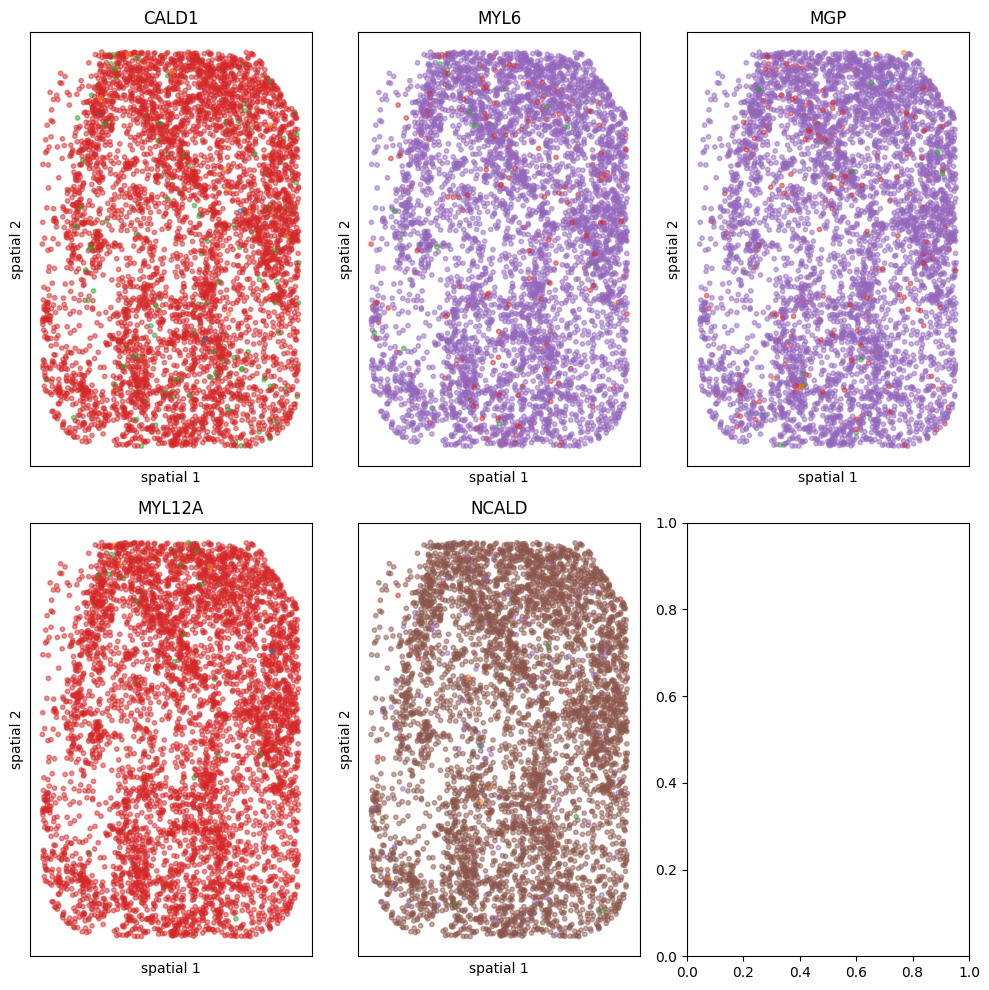

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_subset[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=-node_feat, s=10, alpha=0.5, ax=ax, colorbar=False)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


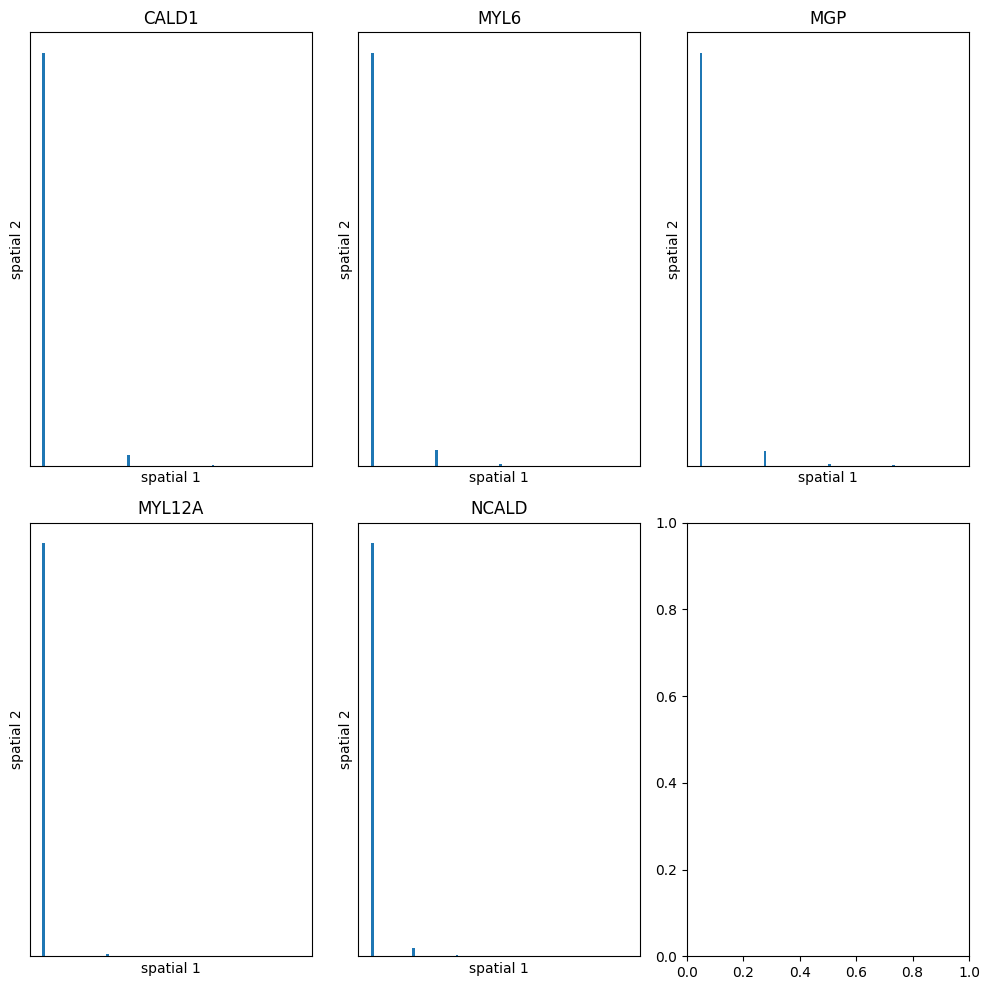

In [54]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_subset[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    ax.hist(node_feat, bins=100)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


In [55]:
adata_subset.shape

(5000, 15936)

In [56]:
import magic
magic_op = magic.MAGIC()
adata_magic = magic_op.fit_transform(adata_subset, genes=markers)

Calculating MAGIC...
  Running MAGIC on 5000 cells and 15936 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...


/home/xs272/.local/lib/python3.9/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculated PCA in 0.33 seconds.
    Calculating KNN search...
    Calculated KNN search in 2.84 seconds.
    Calculating affinities...
    Calculated affinities in 2.82 seconds.
  Calculated graph and diffusion operator in 6.01 seconds.
  Calculating imputation...
Calculated MAGIC in 6.07 seconds.


In [57]:
adata_magic.write_h5ad("../data/A23-290-CP_preprocessed_gentle_subset_magic.h5ad")

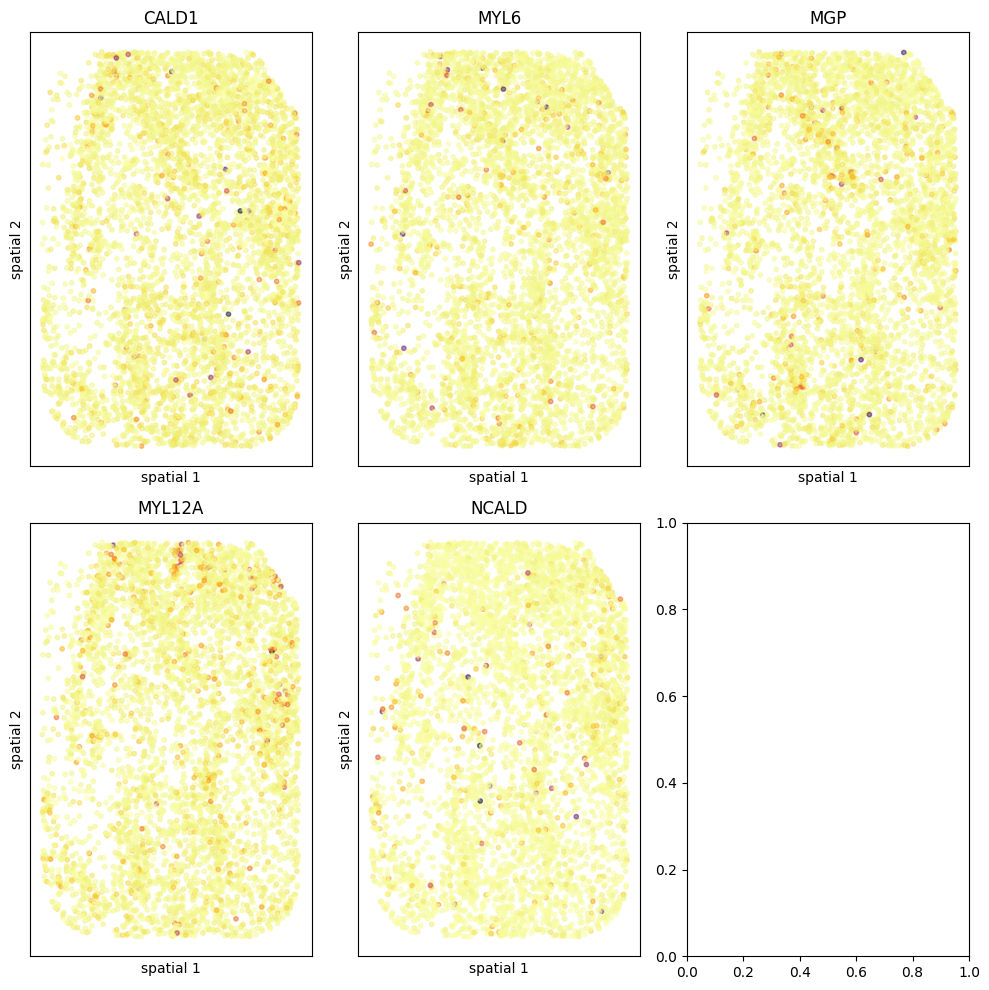

In [58]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_magic[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=-node_feat, s=10, alpha=0.5, ax=ax, colorbar=False)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


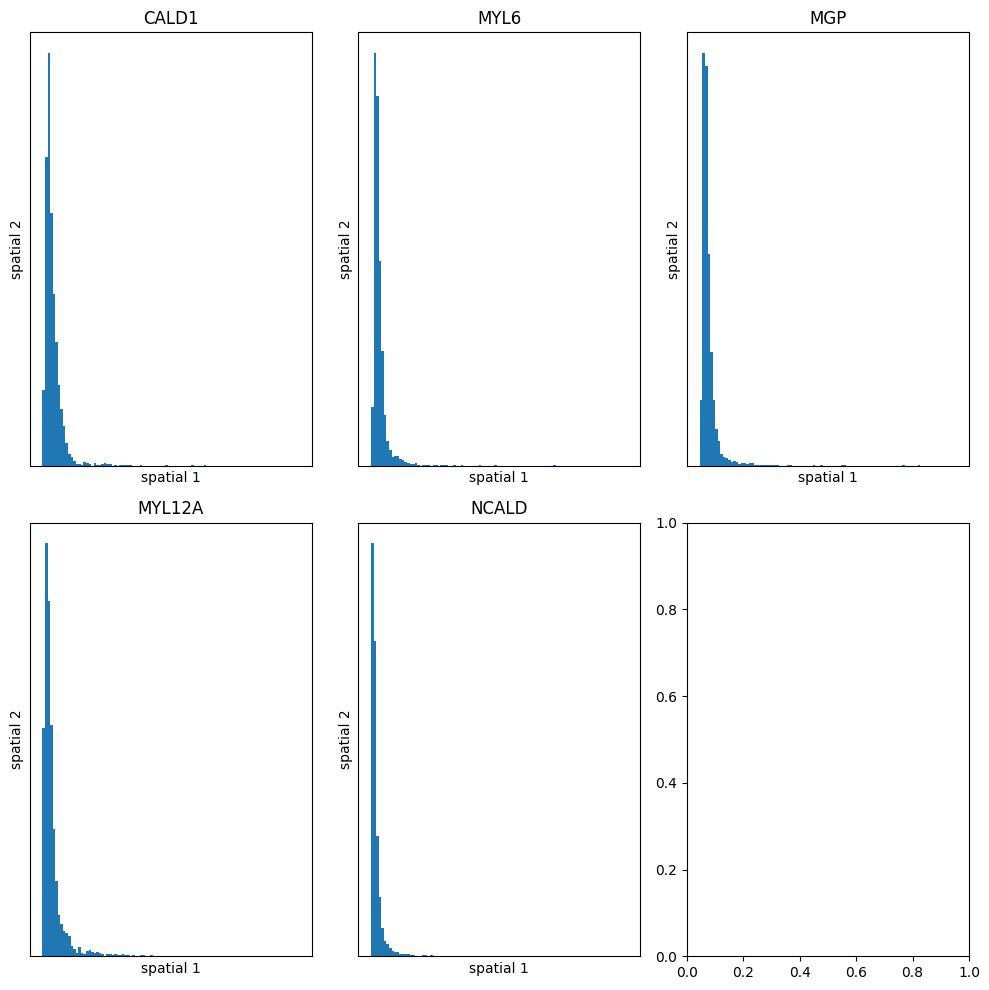

In [59]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_magic[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    ax.hist(node_feat, bins=100)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


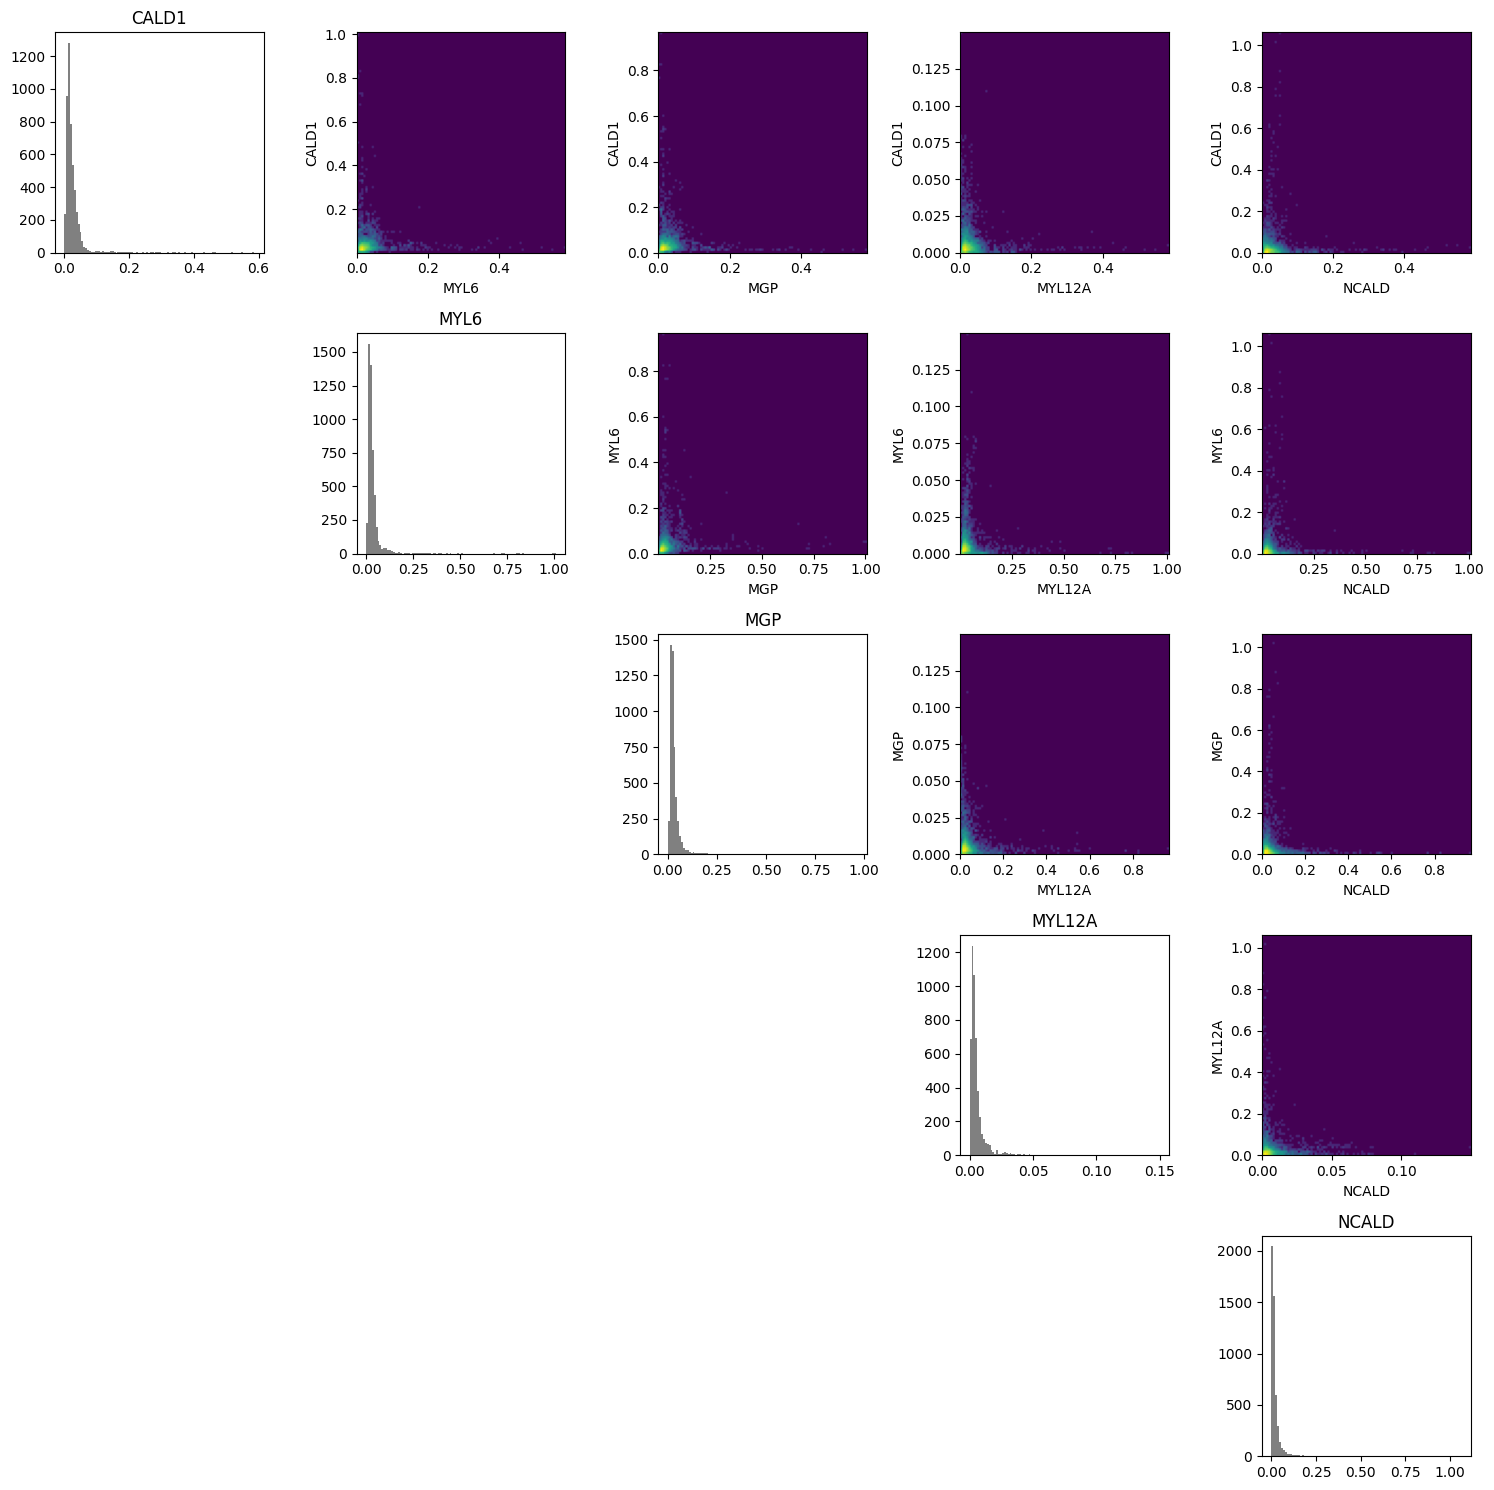

In [60]:
take_log = False
# Assuming `markers` is a list of marker names and `adata_magic` is your dataset
n = len(markers) # Number of markers

fig, axes = plt.subplots(n, n, figsize=(15, 15)) # Create a grid of subplots

for i in range(n):
    for j in range(n):
        if i < j: # Upper off-diagonal, plot heatmap
            node_feat_x = adata_magic[:, markers[i]].X.toarray().flatten()
            node_feat_y = adata_magic[:, markers[j]].X.toarray().flatten()
            if take_log:
                node_feat_x = np.log1p(node_feat_x)
                node_feat_y = np.log1p(node_feat_y)
            # Calculate the density
            x_edges = np.linspace(min(node_feat_x), max(node_feat_x), 100)
            y_edges = np.linspace(min(node_feat_y), max(node_feat_y), 100)
            density, _, _ = np.histogram2d(node_feat_x, node_feat_y, bins=[x_edges, y_edges])

            # Plotting the heatmap
            ax = axes[i, j]
            ax.imshow(np.log1p(density.T), origin='lower',
                      extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
                      aspect='auto', cmap='viridis')
            ax.set_xlabel(markers[j])
            ax.set_ylabel(markers[i])

        elif i == j: # Diagonal, plot histogram
            node_feat = adata_magic[:, markers[i]].X.toarray().flatten()
            if take_log:
                node_feat = np.log1p(node_feat)
            ax = axes[i, j]
            ax.hist(node_feat, bins=100, color='gray')
            ax.set_title(markers[i])

        else: # Lower off-diagonal, clear the plot
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()


In [61]:
model = HyperScatteringModule(in_channels=X_cmbn.shape[1], 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
              reshape=False,
        )

In [62]:
s_nodes, s_edges = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)

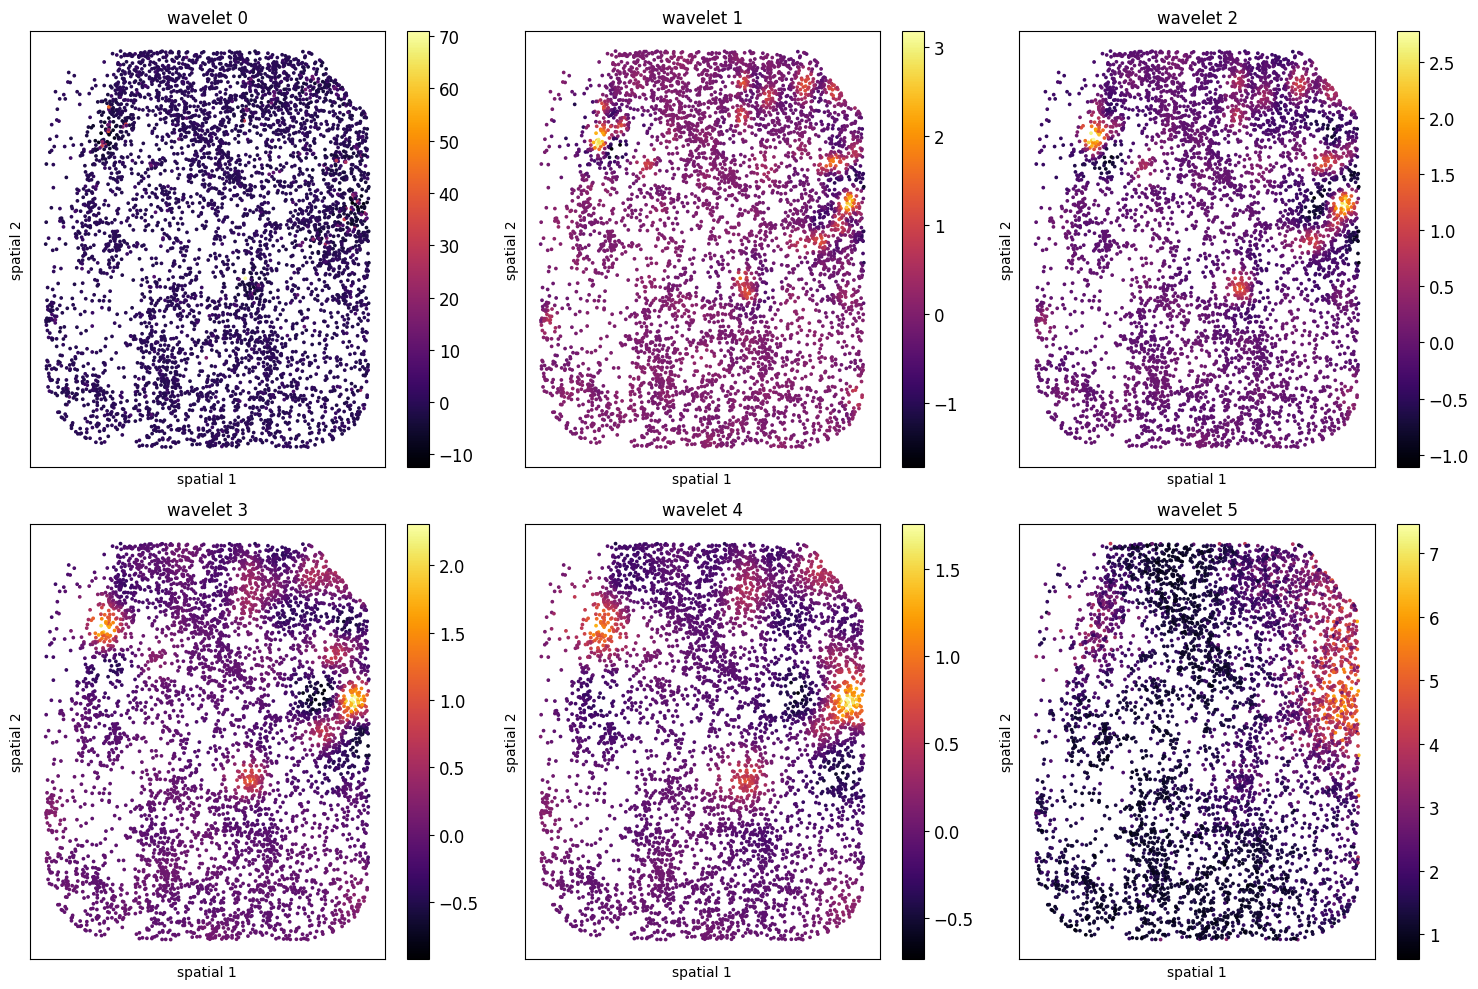

In [63]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    node_feat = s_nodes[0,i,:,0].detach().cpu().numpy()
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=node_feat, ax=ax)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'wavelet {i}')

plt.tight_layout()
plt.show()


In [64]:
s_edges.size()

torch.Size([1, 6, 4999, 100])

In [65]:
shapes = s_edges.size()
he_features = s_edges.squeeze().permute(1,0,2).reshape(shapes[2], shapes[1]*shapes[3])

In [66]:
torch.save(he_features, "../data/A23-290-CP_preprocessed_hvg_subset_hyperedge_GS_features.pt")

get W2 distances between the hyperedges

In [67]:
from hypgs.utils.hyperedge_aggregator import compute_mean, compute_cov
from hypgs.utils.w2 import compute_w2_batch

In [68]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [69]:
markers_tensor = torch.tensor(adata_magic.X, dtype=torch.float32).to(device)

In [70]:
x = markers_tensor.to(device)
edge_index = dataset[0].edge_index.to(device)

In [71]:
x = (x - x.mean()) / x.std()

In [72]:
he_means = compute_mean(x, edge_index)
he_covs = compute_cov(x, edge_index)

In [73]:
from hypgs.utils.w2 import batch_compute_w2_dist, vector_to_square_matrix

In [74]:
n_points = he_means.size(0)
rows, cols = torch.triu_indices(n_points, n_points, offset=1)

In [75]:
# len(rows)

In [76]:
dists = batch_compute_w2_dist(he_means[rows,:], he_means[cols,:], he_covs[rows,...], he_covs[cols,...], 1000)# 

  1%|          | 77/12493 [00:00<00:51, 240.96it/s]

100%|██████████| 12493/12493 [00:13<00:00, 913.65it/s] 


In [77]:
dist_mat = vector_to_square_matrix(dists, n_points)

Text(0.5, 1.0, 'Distributuion of pairwise Wasserstein distances')

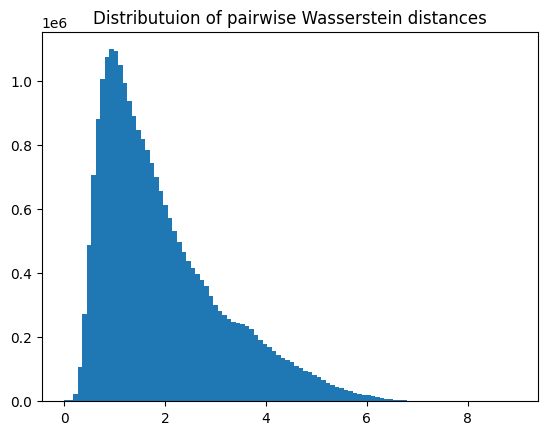

In [78]:
plt.hist(dist_mat.flatten().cpu().numpy(), 100)
plt.title("Distributuion of pairwise Wasserstein distances")

In [79]:
import pathlib

In [80]:
pathlib.Path("../dmae/data/").mkdir(parents=True, exist_ok=True)

In [83]:
from sklearn.model_selection import train_test_split

In [86]:
seed = 42
test_size = 0.2
he_x = he_features.detach().cpu().numpy()
dist_mat_np = dist_mat.detach().cpu().numpy()
colors = np.zeros(dist_mat.shape[0])
ids = np.arange(0, he_x.shape[0])
id_train, _ = train_test_split(ids, test_size=test_size, random_state=seed)
is_train = np.isin(ids, id_train)
phate = np.zeros((he_x.shape[0], 2))
np.savez('../dmae/data/A23_subset_all.npz', data=he_x, phate=he_x[:,:2], dist=dist_mat_np, colors=colors, is_train=is_train)

In [87]:
eidf = get_hyperedge_pos_df(dataset[0], coordinates)
enlarged_hulls = compute_enlarged_hulls(eidf)

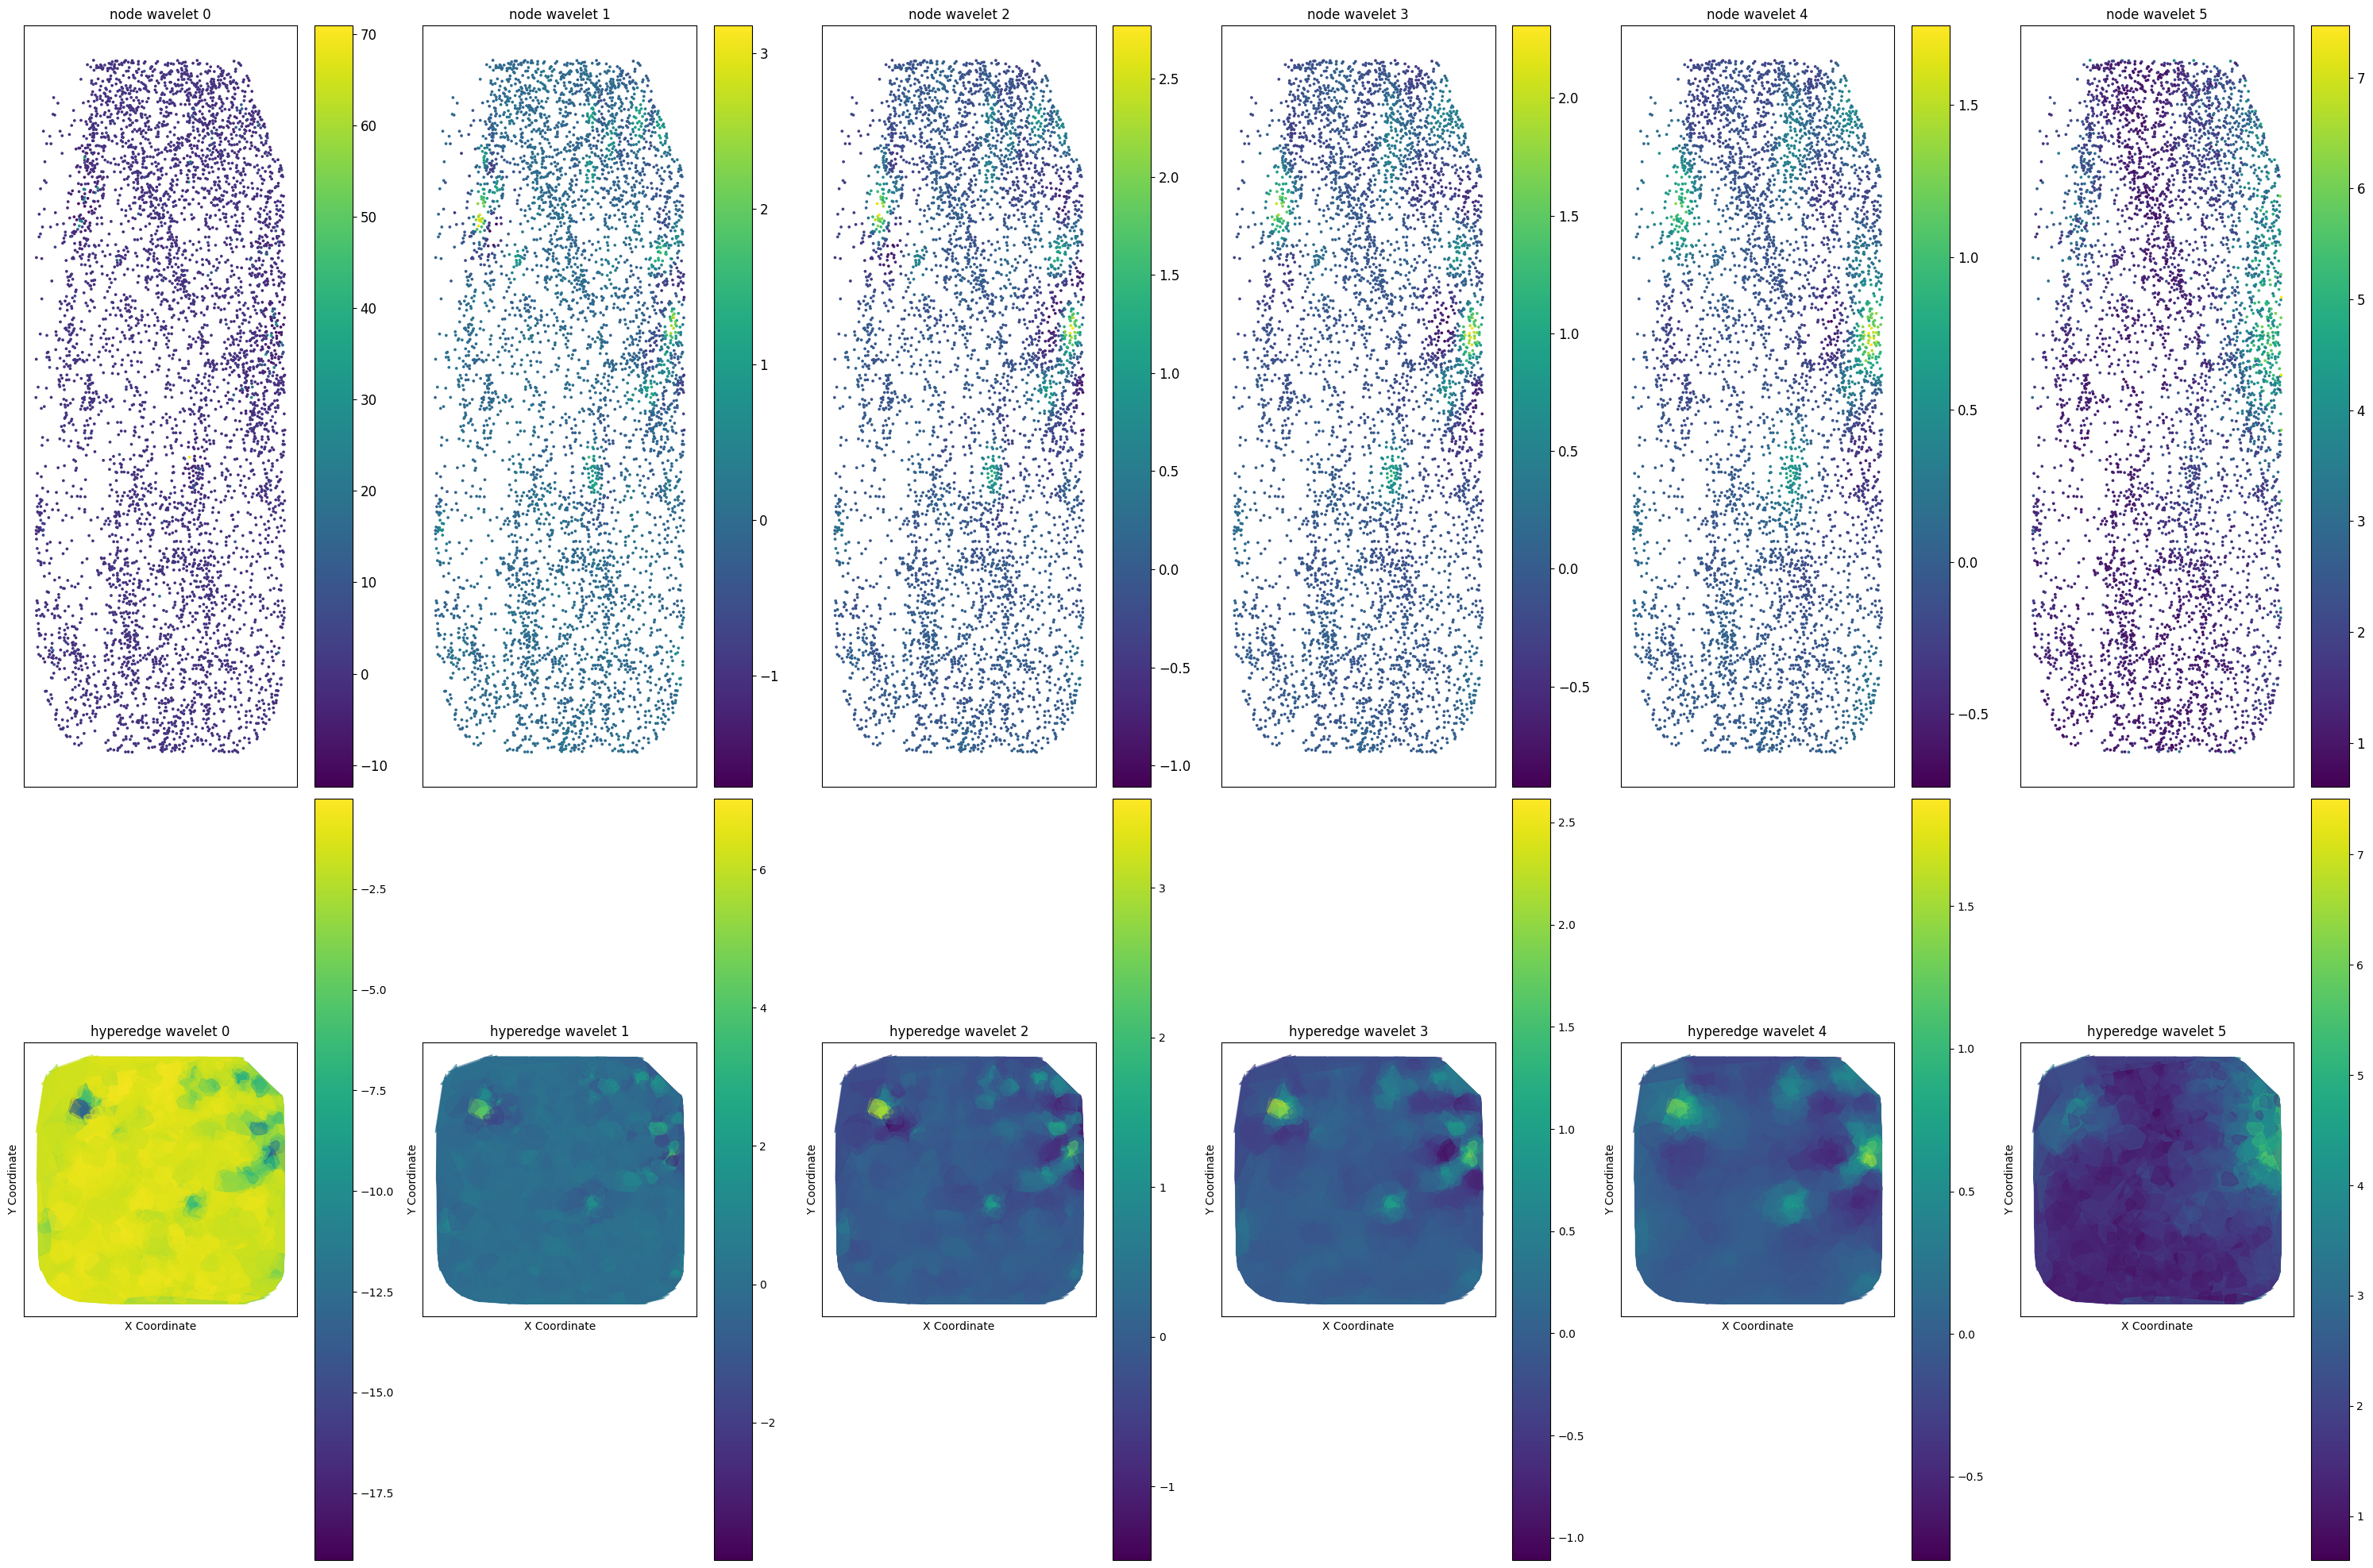

In [88]:
node_feats = s_nodes[0,:,:,0].detach().cpu().numpy().T
edge_feats = s_edges[0,:,:,0].detach().cpu().numpy().T
plot_wavelets(node_feats, edge_feats, coordinates, enlarged_hulls)